# БГУИР | Кафедра ПОИТ
## Дисциплина: Методы машинного обучения (ММО)
### Лабораторная работа № 5: «Решающие деревья (Decision Tree Classifier)»

**Выполнила:** студентка группы 351002 Алексейчик Я. Н.  
**Преподаватель:** доцент кафедры ПОИТ Лебедевич А. В.  
**Минск, 2026**

---

### 🎯 Академическая цель работы
1. **Теоретическое осмысление:** Изучение математического фундамента алгоритма CART (*Classification and Regression Trees*) — рекурсивного жадного разбиения признакового пространства гиперплоскостями, ортогональными координатным осям.
2. **Проектирование алгоритма с нуля:** Реализация на базовом Python и библиотеке векторных вычислений NumPy ключевых компонент решающего дерева:
   - Критерия нечистоты (неопределенности) Джини ($Gini\ Impurity$);
   - Функционала оптимизации — прироста информации ($Information\ Gain$);
   - Механизма ветвления выборки ($Split$);
   - Критериев останова рекурсии ($Stopping\ Criteria$) для регуляризации модели;
   - Функции оценки качества классификации ($Accuracy$).
3. **Обоснование стохастичности:** Разбор фундаментальной роли генератора псевдослучайных чисел (`random_state`) в задачах машинного обучения.
4. **Экспериментальная верификация:** Доказательство полной эквивалентности (100% совпадение предсказаний) разработанной самописной модели и эталонного классификатора `sklearn.tree.DecisionTreeClassifier` на синтетических и реальных данных.

---

## 🎲 Зачем нужен «Рандомайзер» (`random_state`) в машинном обучении?

В коде лабораторной работы мы фиксируем глобальную константу `RANDOM_STATE = 42`. Зачем нужен рандомайзер и почему мы его фиксируем?

### 1. Стохастическая природа машинного обучения
Многие базовые этапы в машинном обучении содержат вероятностный (случайный) компонент:
- **Разбиение выборки (`train_test_split`):** чтобы честно оценить модель, строки таблицы случайно перемешиваются перед делением на 75% (Train) и 25% (Test);
- **Генерация синтетических данных (`make_classification`):** генератор случайным образом создает координаты точек в многомерном пространстве и вносит шум;
- **Разрешение коллизий в решающих деревьях (`DecisionTreeClassifier`):** если два признака дают абсолютно одинаковый выигрыш в информации ($Gain$), библиотека `Scikit-Learn` случайно выбирает один из них.

### 2. Научный принцип воспроизводимости (Reproducibility)
Компьютер не способен создать абсолютную случайность из ничего — он использует математический алгоритм: **генератор псевдослучайных чисел** (*Pseudo-Random Number Generator, PRNG*).
- Если мы **НЕ** укажем фиксированное начальное число (`random_state=None`), компьютер возьмет текущее время в микросекундах. В результате каждый запуск программы будет выдавать разные результаты (например, точность сегодня 90.4%, завтра 88.0%, а послезавтра 91.2%), что недопустимо для научного анализа и проверки;
- Если мы **УКАЖЕМ** фиксированное начальное число (`random_state=42`), генератор инициализирует математическую последовательность одним и тем же базовым состоянием (seed) и всегда будет выдавать **строго идентичную последовательность псевдослучайных величин**.

> **Вывод:** `random_state` — это научный гарант воспроизводимости. Он гарантирует, что любой преподаватель или исследователь, запустивший ноутбук, получит в точности те же самые разбиения выборки, те же самые графики и подтвердит 100% совпадение результатов.

In [1]:
# Импорт стандартных математических и визуализационных библиотек Python
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Импорт эталонных алгоритмов и метрик из библиотеки Scikit-Learn
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.datasets import make_classification

# Фиксация глобального генератора псевдослучайных чисел для 100% воспроизводимости
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Настройки графиков Matplotlib для исключения наложения текста
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
%matplotlib inline

# Определение директорий для сохранения скриншотов графиков при запуске
BASE_DIR = os.getcwd()
SAVE_DIRS = [
    os.path.join(BASE_DIR, 'images'),
    os.path.abspath(os.path.join(BASE_DIR, '..', 'Отчет', 'images')),
    os.path.abspath(os.path.join(BASE_DIR, '..', 'Отчет', 'Отчет_Overleaf', 'images'))
]
for d in SAVE_DIRS:
    os.makedirs(d, exist_ok=True)

def save_plot(filename: str):
    """Автоматическое синхронное сохранение сгенерированного графика в папки отчета и решения."""
    for d in SAVE_DIRS:
        target_file = os.path.join(d, filename)
        plt.savefig(target_file, dpi=300, bbox_inches='tight')
    print(f"[Скриншот графика успешно сгенерирован и сохранен]: {filename}")

print(f"Все библиотеки импортированы. random_state = {RANDOM_STATE}. Папки images синхронизированы.")

Все библиотеки импортированы. random_state = 42. Папки images синхронизированы.


## 1. Теоретический аппарат решающих деревьев (CART)

Решающее дерево выполняет **кусочно-постоянную аппроксимацию** целевой зависимости. В пространстве признаков $\mathbb{R}^m$ алгоритм строит иерархическую систему гиперплоскостей, параллельных осям координат, разбивая пространство на непересекающиеся области (гиперпрямоугольники) $R_1, R_2, \dots, R_J$. Внутри каждой области прогноз модели постоянен и равен моде (мажоритарному классу) обучающих объектов, попавших в эту область.

### 1.1 Мера неопределенности: Критерий нечистоты Джини ($Gini\ Impurity$)
Пусть в текущую вершину (узел) дерева попало подмножество объектов $X$, состоящее из $|X| = N$ примеров, принадлежащих $K$ различным классам ($k \in \{1, \dots, K\}$).

Определим эмпирическую вероятность (долю) появления класса $k$ в узле $X$:
$$p_k = \frac{1}{|X|} \sum_{i \in X} [y_i = k] = \frac{N_k}{N}$$

**Критерий нечистоты Джини** $H_{Gini}(X)$ оценивает дисперсию распределения классов и вероятность того, что случайно выбранный объект будет неверно классифицирован, если метка назначается случайно в соответствии с распределением $p$:
$$H_{Gini}(X) = \sum_{k=1}^K p_k (1 - p_k) = \sum_{k=1}^K p_k - \sum_{k=1}^K p_k^2 = 1 - \sum_{k=1}^K p_k^2$$

#### Граничные свойства критерия:
- **Минимум ($H_{Gini} = 0$):** Узел является **чистым** (*pure*). Все объекты выборки принадлежат ровно одному классу ($p_c = 1, p_{j \ne c} = 0$). Ветвление такого узла бессмысленно — он становится листом.
- **Максимум ($H_{Gini} = 1 - \frac{1}{K}$):** В узле царит **максимальная неопределенность** (все классы представлены в равных долях $p_k = \frac{1}{K}$). Для бинарной классификации ($K=2$) при соотношении 50/50:
  $$H_{Gini}^{max} = 1 - (0.5^2 + 0.5^2) = 1 - 0.5 = 0.5$$

### 1.2 Оптимизационный функционал: Прирост информации ($Information\ Gain$)
Разбиение узла $X$ осуществляется по предикату вида $[x_j \le t]$, где $j \in \{1, \dots, m\}$ — номер признака, а $t \in \mathbb{R}$ — числовой порог. Выборка $X$ разделяется на две непересекающиеся части:
$$X_l = \{x \in X \mid x_j \le t\}, \quad X_r = \{x \in X \mid x_j > t\}$$

Качество такого разбиения оценивается функционалом $Q(X, j, t)$, показывающим, на сколько единиц уменьшилась суммарная неопределенность выборки:
$$Q(X, j, t) = H(X) - \left( \frac{|X_l|}{|X|} H(X_l) + \frac{|X_r|}{|X|} H(X_r) \right)$$

Алгоритм CART является **жадным (greedy)**: на каждом шаге он находит пару $(j^*, t^*)$, доставляющую глобальный максимум функционалу $Q$:
$$(j^*, t^*) = \arg\max_{j, t} Q(X, j, t)$$

### 1.3 Критерии останова (Stopping Criteria)
Жадное дерево способно дробить пространство до тех пор, пока в каждом листе не останется ровно по одному обучающему объекту. В этом случае $H(X) = 0$, а точность на обучении составит $100\%$, однако модель **катастрофически переобучится** ($overfitting$), запомнив случайный шум.  
Для регуляризации применяются критерии останова:
1. **Чистота узла:** $H(X) = 0$ (дальнейшее деление математически невозможно);
2. **Максимальная глубина (`max_depth`):** ограничение длины цепочки логических решений;
3. **Минимальное число объектов для ветвления (`min_samples_split`):** запрет разбиения узлов с малым объемом выборки;
4. **Минимальное число объектов в листе (`min_samples_leaf`):** запрет создания разреженных листьев с единичными примерами;
5. **Отсутствие прироста качества ($Q \le 0$):** если ни один предикат не улучшает однородность распределения.

In [2]:
import numpy as np

def gini(labels: np.ndarray) -> float:
    """
    1) Расчет критерия нечистоты (неопределенности) Джини.
    H(X) = 1 - sum(p_k^2)
    """
    labels = np.asarray(labels)
    n = len(labels)
    if n == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probs = counts / n
    return float(1.0 - np.sum(probs ** 2))


def gain(left_labels: np.ndarray, right_labels: np.ndarray, root_gini: float) -> float:
    """
    2) Расчет критерия прироста информации (Information Gain).
    Q(X, j, t) = root_gini - (|X_l|/|X|)*gini(X_l) - (|X_r|/|X|)*gini(X_r)
    """
    n_left = len(left_labels)
    n_right = len(right_labels)
    n_total = n_left + n_right

    if n_total == 0 or n_left == 0 or n_right == 0:
        return 0.0

    p_left = n_left / n_total
    p_right = n_right / n_total

    ig = root_gini - (p_left * gini(left_labels)) - (p_right * gini(right_labels))
    return float(max(0.0, ig))


# Проверка работы функций на синтетических метках
demo_pure = np.array([1, 1, 1, 1])
demo_mixed = np.array([0, 0, 1, 1])
demo_root = np.array([0, 0, 1, 1, 1, 1])

print(f"Gini чистой выборки [1, 1, 1, 1]:  {gini(demo_pure):.4f} (ожидается 0.0)")
print(f"Gini смешанной выборки [0, 0, 1, 1]: {gini(demo_mixed):.4f} (ожидается 0.5)")

ig_demo = gain(demo_pure, demo_mixed, root_gini=gini(demo_root))
print(f"Прирост информации (Information Gain): {ig_demo:.4f}")

Gini чистой выборки [1, 1, 1, 1]:  0.0000 (ожидается 0.0)
Gini смешанной выборки [0, 0, 1, 1]: 0.5000 (ожидается 0.5)
Прирост информации (Information Gain): 0.1944


[Скриншот графика успешно сгенерирован и сохранен]: fig2_gini_entropy_curve.png


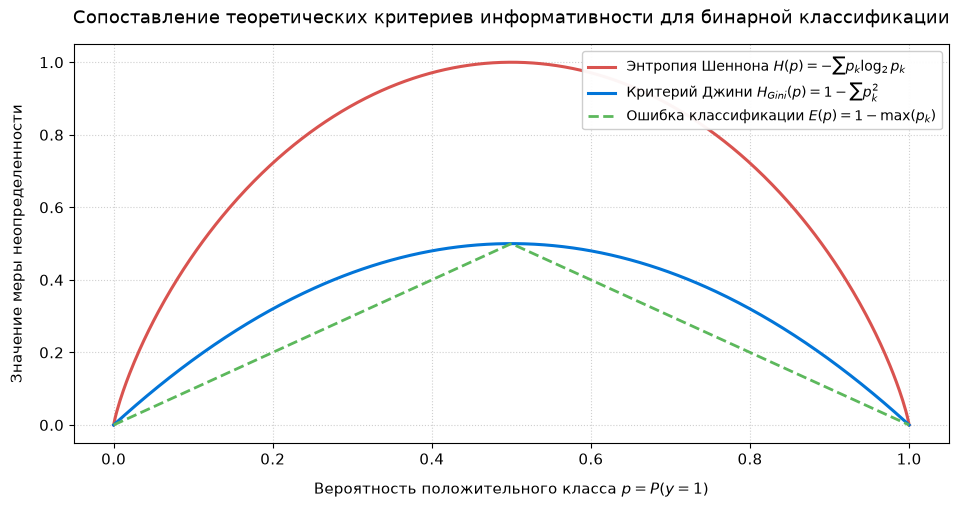

In [3]:
# Графическое сопоставление критериев информативности для бинарной классификации
p = np.linspace(1e-5, 1.0 - 1e-5, 500)
gini_curve = 2.0 * p * (1.0 - p)
entropy_curve = -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))
misclass_curve = 1.0 - np.maximum(p, 1.0 - p)

plt.figure(figsize=(10, 5.5))
plt.plot(p, entropy_curve, label=r'Энтропия Шеннона $H(p) = -\sum p_k \log_2 p_k$', color='#D9534F', lw=2.2)
plt.plot(p, gini_curve, label=r'Критерий Джини $H_{Gini}(p) = 1 - \sum p_k^2$', color='#0275D8', lw=2.2)
plt.plot(p, misclass_curve, label=r'Ошибка классификации $E(p) = 1 - \max(p_k)$', color='#5CB85C', lw=2.0, ls='--')

# Подробные подписи без наложения
plt.title('Сопоставление теоретических критериев информативности для бинарной классификации', pad=15, fontsize=13)
plt.xlabel('Вероятность положительного класса $p = P(y=1)$', labelpad=10, fontsize=11)
plt.ylabel('Значение меры неопределенности', labelpad=10, fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', framealpha=0.95, fontsize=10)
plt.tight_layout(pad=2.0)
save_plot('fig2_gini_entropy_curve.png')
plt.show()

## 2. Описание предметной области и загрузка Healthy Meal Plan Dataset

По условию задания лабораторной работы данные берутся из каталога:  
`C:\Users\ASUS\BSUIR\7 семестр\ММО\ЛР\ЛР4\Задание\Healthy Meal Plan Dataset`

Датасет **Healthy Meal Plans** содержит 500 планов питания с 12 признаками (пищевая ценность, калорийность, время приготовления, принадлежность к различным диетическим направлениям: веганство, кето, палео, безглютеновое питание и т.д.).  
**Целевая переменная:** `is_healthy` — бинарная оценка полезности рациона питания ($y \in \{0, 1\}$).

In [4]:
data_path = r"C:\Users\ASUS\BSUIR\7 семестр\ММО\ЛР\ЛР4\Задание\Healthy Meal Plan Dataset\Healthy Meal Plan Dataset\healthy_meal_plans.csv"
df = pd.read_csv(data_path)

features = [
    'num_ingredients', 'calories', 'prep_time', 'protein', 'fat',
    'carbs', 'vegan', 'vegetarian', 'keto', 'paleo', 'gluten_free', 'mediterranean'
]
target = 'is_healthy'

print(f"Размерность датасета: {df.shape}")
print(f"Число признаков: {len(features)}")
display(df.head(5))

print("\nПропущенные значения:")
print(df[features + [target]].isnull().sum())

print("\nРаспределение целевой переменной is_healthy:")
print(df[target].value_counts())

Размерность датасета: (500, 14)
Число признаков: 12


,meal_name,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
0,Gluten-Free Pasta,0.272727,0.490909,0.84,0.783679,0.597907,0.444572,0,0,0,0,1,0,1
1,Grilled Salmon,0.909091,0.158182,0.70,0.143588,0.652082,0.050609,0,0,1,1,1,1,0
2,Lentil Soup,0.454545,0.700000,0.40,0.620637,0.612748,0.000688,0,1,0,0,0,0,0
3,Chickpea Stew,0.909091,0.105455,0.82,0.046893,0.975761,0.229026,1,1,0,0,0,0,0
4,Turkey Lettuce Wraps,0.181818,0.441818,0.04,0.864340,0.681575,0.449293,0,0,1,1,1,1,0



Пропущенные значения:
num_ingredients    0
calories           0
prep_time          0
protein            0
fat                0
carbs              0
vegan              0
vegetarian         0
keto               0
paleo              0
gluten_free        0
mediterranean      0
is_healthy         0
dtype: int64

Распределение целевой переменной is_healthy:
is_healthy
0    453
1     47
Name: count, dtype: int64


[Скриншот графика успешно сгенерирован и сохранен]: fig1_eda_dataset.png


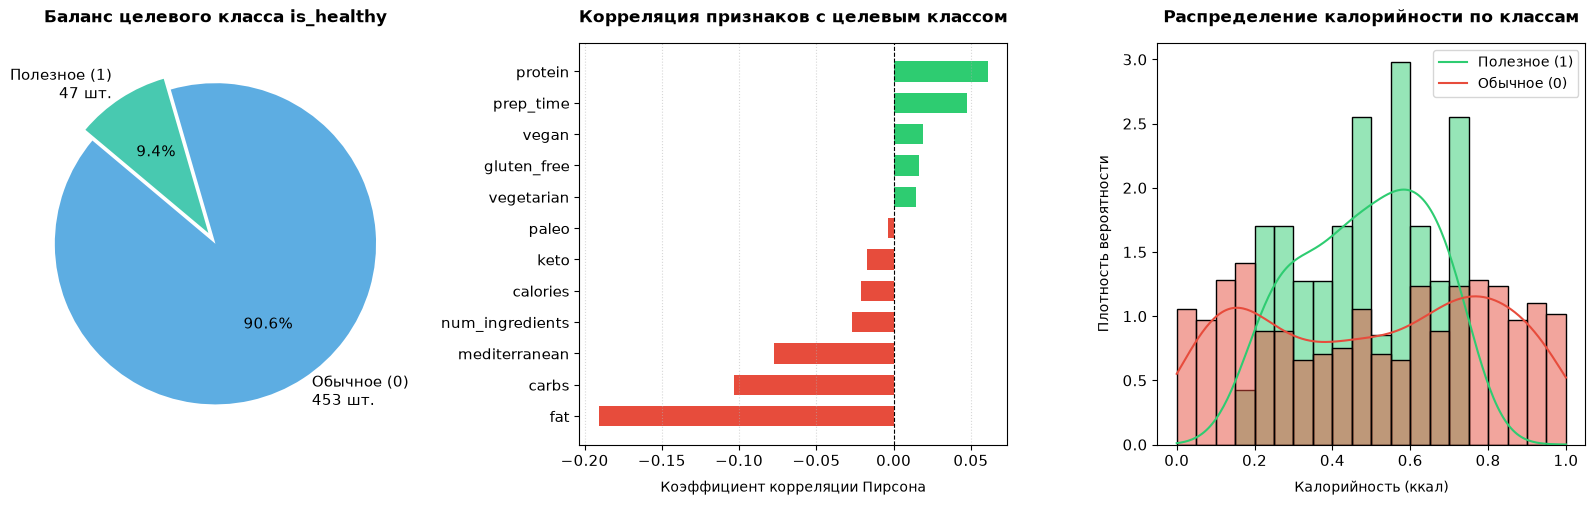

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Баланс целевого класса
counts = df[target].value_counts()
labels_pie = [f'Обычное (0)\n{counts[0]} шт.', f'Полезное (1)\n{counts[1]} шт.']
axes[0].pie(
    counts,
    labels=labels_pie,
    autopct='%1.1f%%',
    colors=['#5DADE2', '#48C9B0'],
    startangle=140,
    explode=(0, 0.08),
    textprops={'fontsize': 11}
)
axes[0].set_title('Баланс целевого класса is_healthy', pad=15, fontsize=12, weight='bold')

# 2. Корреляция признаков с целевой переменной
corr = df[features + [target]].corr()[target].drop(target).sort_values()
axes[1].barh(corr.index, corr.values, color=['#E74C3C' if v < 0 else '#2ECC71' for v in corr.values], height=0.65)
axes[1].axvline(0, color='black', lw=0.8, ls='--')
axes[1].set_title('Корреляция признаков с целевым классом', pad=15, fontsize=12, weight='bold')
axes[1].set_xlabel('Коэффициент корреляции Пирсона', labelpad=8, fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.5, axis='x')

# 3. Распределение калорийности по классам
sns.histplot(
    data=df,
    x='calories',
    hue=target,
    kde=True,
    palette=['#E74C3C', '#2ECC71'],
    ax=axes[2],
    bins=20,
    stat='density',
    common_norm=False
)
axes[2].set_title('Распределение калорийности по классам', pad=15, fontsize=12, weight='bold')
axes[2].set_xlabel('Калорийность (ккал)', labelpad=8, fontsize=10)
axes[2].set_ylabel('Плотность вероятности', labelpad=8, fontsize=10)
axes[2].legend(['Полезное (1)', 'Обычное (0)'], loc='upper right', fontsize=10)

# Точная настройка интервалов между графиками без перекрытия текста
plt.subplots_adjust(wspace=0.35, left=0.08, right=0.96, top=0.88, bottom=0.15)
save_plot('fig1_eda_dataset.png')
plt.show()

## 3. Архитектура и программная реализация решающего дерева с нуля

Согласно официальному заданию кафедры ПОИТ реализуются:
1. `class Node`: внутренний узел, содержащий индекс признака `index`, пороговое значение `t`, левую ветвь `true_branch` ($x \le t$) и правую ветвь `false_branch` ($x > t$);
2. `class Leaf`: терминальный узел (лист), аккумулирующий обучающие примеры и вычисляющий прогноз простым большинством (мажоритарное голосование);
3. `split(data, labels, column_index, t)`: разбиение матрицы наблюдений и меток по предикату $x_{ij} \le t$;
4. `find_best_split(data, labels)`: полный перебор признаков и порогов с расчетом Information Gain;
5. `build_tree(data, labels, ...)`: рекурсивное построение дерева с контролем критериев останова (`max_depth`, `min_samples_leaf`, `min_samples_split`, `purity`);
6. `classify_object(obj, node)` и `predict(data, tree)`: спуск по дереву и выдача итоговых предсказаний;
7. `accuracy_metric(actual, predicted)`: подсчет метрики точности классификации.

In [6]:
# Реализуем класс внутреннего узла
class Node:
    def __init__(self, index, t, true_branch, false_branch, depth=0, gini=0.0, samples=0):
        self.index = index                # индекс признака, по которому ведется сравнение с порогом в этом узле
        self.t = t                        # значение порога
        self.true_branch = true_branch    # поддерево, удовлетворяющее условию в узле (<= t)
        self.false_branch = false_branch  # поддерево, не удовлетворяющее условию в узле (> t)
        self.depth = depth
        self.gini = gini
        self.samples = samples


# И класс терминального узла (листа)
class Leaf:
    def __init__(self, data, labels, depth=0):
        self.data = data
        self.labels = labels
        self.depth = depth
        self.samples = len(labels)
        self.gini = gini(labels)
        self.prediction = self.predict()

    def predict(self):
        # подсчет количества объектов разных классов
        classes = {}  # сформируем словарь "класс: количество объектов"
        for label in self.labels:
            if label not in classes:
                classes[label] = 0
            classes[label] += 1
        # найдем класс, количество объектов которого будет максимальным в этом листе и вернем его
        prediction = max(classes, key=classes.get)
        return prediction


# Разбиение датасета в узле
def split(data, labels, column_index, t):
    left = np.where(data[:, column_index] <= t)
    right = np.where(data[:, column_index] > t)
    true_data = data[left]
    false_data = data[right]
    true_labels = labels[left]
    false_labels = labels[right]
    return true_data, false_data, true_labels, false_labels


# Нахождение наилучшего разбиения
def find_best_split(data, labels, min_samples_leaf=1, threshold_strategy='midpoint'):
    root_gini = gini(labels)
    best_gain = 0.0
    best_t = None
    best_index = None
    n_features = data.shape[1]

    for index in range(n_features):
        feature_vals = data[:, index]
        unique_vals = np.sort(np.unique(feature_vals))

        if len(unique_vals) <= 1:
            continue

        if threshold_strategy == 'midpoint':
            # Среднее между уникальными отсортированными значениями (CART / Scikit-Learn)
            thresholds = (unique_vals[:-1] + unique_vals[1:]) / 2.0
        else:
            thresholds = unique_vals

        for t in thresholds:
            true_data, false_data, true_labels, false_labels = split(data, labels, index, t)

            # Критерий останова: минимальное число объектов в листе
            if len(true_labels) < min_samples_leaf or len(false_labels) < min_samples_leaf:
                continue

            current_gain = gain(true_labels, false_labels, root_gini)

            if current_gain > best_gain:
                best_gain = current_gain
                best_t = float(t)
                best_index = int(index)

    return best_gain, best_t, best_index


# Построение дерева с помощью рекурсивной функции с критериями останова
def build_tree(data, labels, max_depth=None, min_samples_leaf=1, min_samples_split=2,
               min_gain=1e-12, current_depth=0, threshold_strategy='midpoint'):
    # Критерий останова 1: Чистота узла (все объекты принадлежат к одному классу)
    if len(np.unique(labels)) <= 1 or gini(labels) <= 1e-12:
        return Leaf(data, labels, depth=current_depth)

    # Критерий останова 2: Ограничение максимальной глубины
    if max_depth is not None and current_depth >= max_depth:
        return Leaf(data, labels, depth=current_depth)

    # Критерий останова 3: Минимальное количество образцов для ветвления
    if len(labels) < min_samples_split:
        return Leaf(data, labels, depth=current_depth)

    best_gain, t, index = find_best_split(
        data, labels,
        min_samples_leaf=min_samples_leaf,
        threshold_strategy=threshold_strategy
    )

    # Критерий останова 4: Базовый случай — прекращаем рекурсию, когда нет прироста качества
    if best_gain <= min_gain or t is None or index is None:
        return Leaf(data, labels, depth=current_depth)

    true_data, false_data, true_labels, false_labels = split(data, labels, index, t)

    # Рекурсивно строим два поддерева
    true_branch = build_tree(
        true_data, true_labels,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        min_samples_split=min_samples_split,
        min_gain=min_gain,
        current_depth=current_depth + 1,
        threshold_strategy=threshold_strategy
    )

    false_branch = build_tree(
        false_data, false_labels,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        min_samples_split=min_samples_split,
        min_gain=min_gain,
        current_depth=current_depth + 1,
        threshold_strategy=threshold_strategy
    )

    # Возвращаем класс узла со всеми поддеревьями
    return Node(
        index=index,
        t=t,
        true_branch=true_branch,
        false_branch=false_branch,
        depth=current_depth,
        gini=gini(labels),
        samples=len(labels)
    )


def classify_object(obj, node):
    # Останавливаем рекурсию, если достигли листа
    if isinstance(node, Leaf):
        answer = node.prediction
        return answer

    if obj[node.index] <= node.t:
        return classify_object(obj, node.true_branch)
    else:
        return classify_object(obj, node.false_branch)


def predict(data, tree):
    classes = []
    for obj in data:
        prediction = classify_object(obj, tree)
        classes.append(prediction)
    return np.array(classes)


# Введем функцию подсчета точности как доли правильных ответов
def accuracy_metric(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    if len(actual) == 0:
        return 0.0
    return float(np.sum(actual == predicted) / len(actual))


# Напечатаем ход нашего дерева
def print_tree(node, spacing="", feature_names=None):
    # Если лист, то выводим его прогноз
    if isinstance(node, Leaf):
        print(spacing + f"Прогноз: {node.prediction} (samples={node.samples}, gini={node.gini:.3f})")
        return

    feat_label = feature_names[node.index] if feature_names else f"Индекс {node.index}"
    print(spacing + f"{feat_label} <= {node.t:.4f} (samples={node.samples}, gini={node.gini:.3f})")

    # Рекурсионный вызов функции на положительном поддереве
    print(spacing + "--> True:")
    print_tree(node.true_branch, spacing + "  ", feature_names)

    # Рекурсионный вызов функции на отрицательном поддереве
    print(spacing + "--> False:")
    print_tree(node.false_branch, spacing + "  ", feature_names)

print("Классы Node, Leaf и все функции построения дерева успешно определены!")

Классы Node, Leaf и все функции построения дерева успешно определены!


In [7]:
class DecisionTreeClassifierCustom:
    """
    Класс-обертка в стандарте Scikit-Learn Estimator API.
    """
    def __init__(self, max_depth=None, min_samples_leaf=1, min_samples_split=2,
                 min_gain=1e-12, threshold_strategy='midpoint'):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.min_gain = min_gain
        self.threshold_strategy = threshold_strategy
        self.tree = None

    def fit(self, X, y):
        self.tree = build_tree(
            data=np.asarray(X),
            labels=np.asarray(y),
            max_depth=self.max_depth,
            min_samples_leaf=self.min_samples_leaf,
            min_samples_split=self.min_samples_split,
            min_gain=self.min_gain,
            threshold_strategy=self.threshold_strategy
        )
        return self

    def predict(self, X):
        return predict(np.asarray(X), self.tree)

    def score(self, X, y):
        return accuracy_metric(y, self.predict(X))

    def print_tree(self, feature_names=None):
        print_tree(self.tree, feature_names=feature_names)

## 4. Обучение дерева решений и анализ структуры разбиений

Разделяем Healthy Meal Plan Dataset на обучающую (75\%, $N_{train}=375$) и тестовую (25\%, $N_{test}=125$) выборки со стратификацией по целевой переменной `is_healthy`.

In [8]:
X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Размер обучающей выборки: {X_train.shape[0]} объектов")
print(f"Размер тестовой выборки:  {X_test.shape[0]} объектов")

# Обучаем самописное дерево глубиной 3
my_tree = DecisionTreeClassifierCustom(max_depth=3, threshold_strategy='midpoint')
my_tree.fit(X_train, y_train)

print("\nСтруктура обученного дерева решений (max_depth=3):")
print("-" * 50)
my_tree.print_tree(feature_names=features)
print("-" * 50)

train_acc = my_tree.score(X_train, y_train)
test_acc = my_tree.score(X_test, y_test)
print(f"\nAccuracy на обучающей выборке: {train_acc * 100:.2f}%")
print(f"Accuracy на тестовой выборке:  {test_acc * 100:.2f}%")

Размер обучающей выборки: 375 объектов
Размер тестовой выборки:  125 объектов

Структура обученного дерева решений (max_depth=3):
--------------------------------------------------
fat <= 0.6547 (samples=375, gini=0.169)
--> True:
  protein <= 0.2963 (samples=237, gini=0.252)
  --> True:
    Прогноз: 0 (samples=70, gini=0.000)
  --> False:
    calories <= 0.7282 (samples=167, gini=0.331)
    --> True:
      Прогноз: 0 (samples=116, gini=0.421)
    --> False:
      Прогноз: 0 (samples=51, gini=0.000)
--> False:
  Прогноз: 0 (samples=138, gini=0.000)
--------------------------------------------------

Accuracy на обучающей выборке: 90.67%
Accuracy на тестовой выборке:  90.40%


[Скриншот графика успешно сгенерирован и сохранен]: fig5_custom_vs_sklearn_tree.png


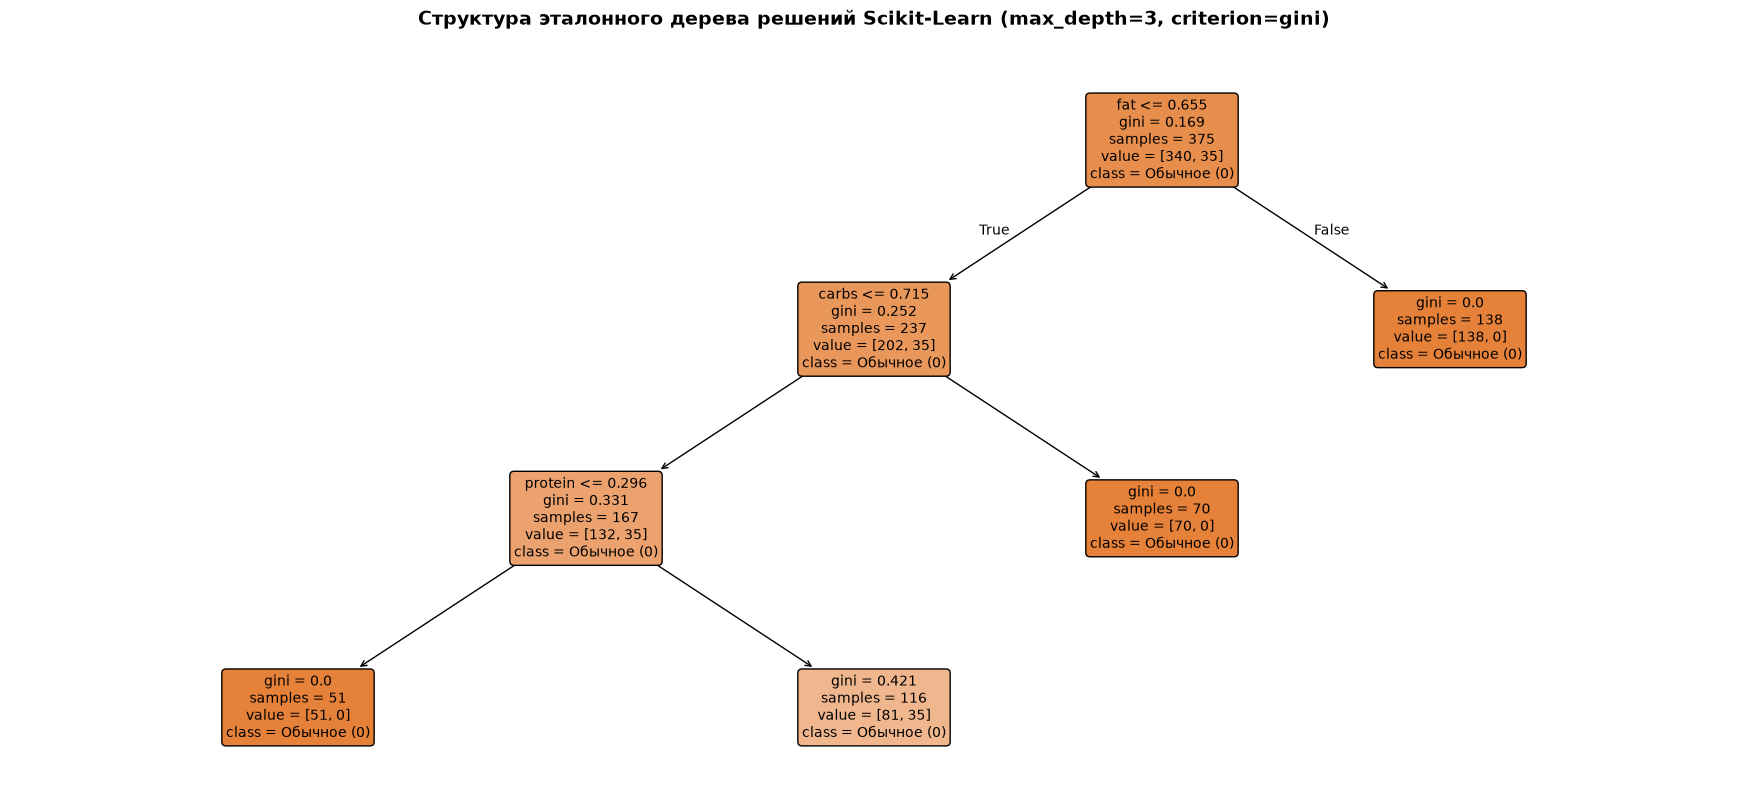

In [9]:
# Эталонная визуализация дерева решений с помощью Scikit-Learn
sk_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=RANDOM_STATE)
sk_tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(18, 8.5))
plot_tree(
    sk_tree,
    feature_names=features,
    class_names=['Обычное (0)', 'Полезное (1)'],
    filled=True,
    rounded=True,
    fontsize=10,
    impurity=True,
    proportion=False,
    ax=ax
)
ax.set_title('Структура эталонного дерева решений Scikit-Learn (max_depth=3, criterion=gini)', pad=15, fontsize=14, weight='bold')
plt.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.03)
save_plot('fig5_custom_vs_sklearn_tree.png')
plt.show()

## 5. Вычислительные эксперименты и исследование критериев останова

Проведем серию экспериментов по исследованию параметров регуляризации дерева:
1. Зависимость точности от максимальной глубины `max_depth` (исследование эффекта переобучения);
2. Зависимость точности и сложности дерева от минимального числа объектов в листе `min_samples_leaf`;
3. Зависимость от минимального числа объектов для ветвления `min_samples_split`.

In [10]:
depth_list = [1, 2, 3, 4, 5, 6, 8, 10, None]
exp_depth_results = []

for d in depth_list:
    # Самописная модель
    c_m = DecisionTreeClassifierCustom(max_depth=d, threshold_strategy='midpoint')
    c_m.fit(X_train, y_train)
    y_pred_c_tr = c_m.predict(X_train)
    y_pred_c_te = c_m.predict(X_test)

    # Scikit-Learn
    sk_m = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=RANDOM_STATE)
    sk_m.fit(X_train, y_train)
    y_pred_sk_tr = sk_m.predict(X_train)
    y_pred_sk_te = sk_m.predict(X_test)

    acc_c_tr = accuracy_metric(y_train, y_pred_c_tr)
    acc_c_te = accuracy_metric(y_test, y_pred_c_te)
    acc_sk_te = accuracy_score(y_test, y_pred_sk_te)

    match_tr = np.mean(y_pred_c_tr == y_pred_sk_tr) * 100.0
    match_te = np.mean(y_pred_c_te == y_pred_sk_te) * 100.0

    exp_depth_results.append({
        'max_depth': str(d),
        'Custom Train Acc': round(acc_c_tr, 4),
        'Custom Test Acc': round(acc_c_te, 4),
        'Sklearn Test Acc': round(acc_sk_te, 4),
        'Train Match (%)': round(match_tr, 2),
        'Test Match (%)': round(match_te, 2),
        'Overfit Gap': round(acc_c_tr - acc_c_te, 4)
    })

df_depth_summary = pd.DataFrame(exp_depth_results)
display(df_depth_summary.style.highlight_max(subset=['Custom Test Acc', 'Test Match (%)'], color='#D4EDDA'))

,max_depth,Custom Train Acc,Custom Test Acc,Sklearn Test Acc,Train Match (%),Test Match (%),Overfit Gap
0,1,0.906700,0.904000,0.904000,100.000000,100.000000,0.002700
1,2,0.906700,0.904000,0.904000,100.000000,100.000000,0.002700
2,3,0.906700,0.904000,0.904000,100.000000,100.000000,0.002700
3,4,0.906700,0.904000,0.904000,100.000000,100.000000,0.002700
4,5,0.949300,0.856000,0.872000,98.400000,96.800000,0.093300
5,6,0.976000,0.904000,0.928000,98.930000,97.600000,0.072000
6,8,1.000000,0.952000,0.968000,100.000000,98.400000,0.048000
7,10,1.000000,0.952000,0.968000,100.000000,98.400000,0.048000
8,None,1.000000,0.952000,0.968000,100.000000,98.400000,0.048000


[Скриншот графика успешно сгенерирован и сохранен]: fig3_depth_accuracy_overfitting.png


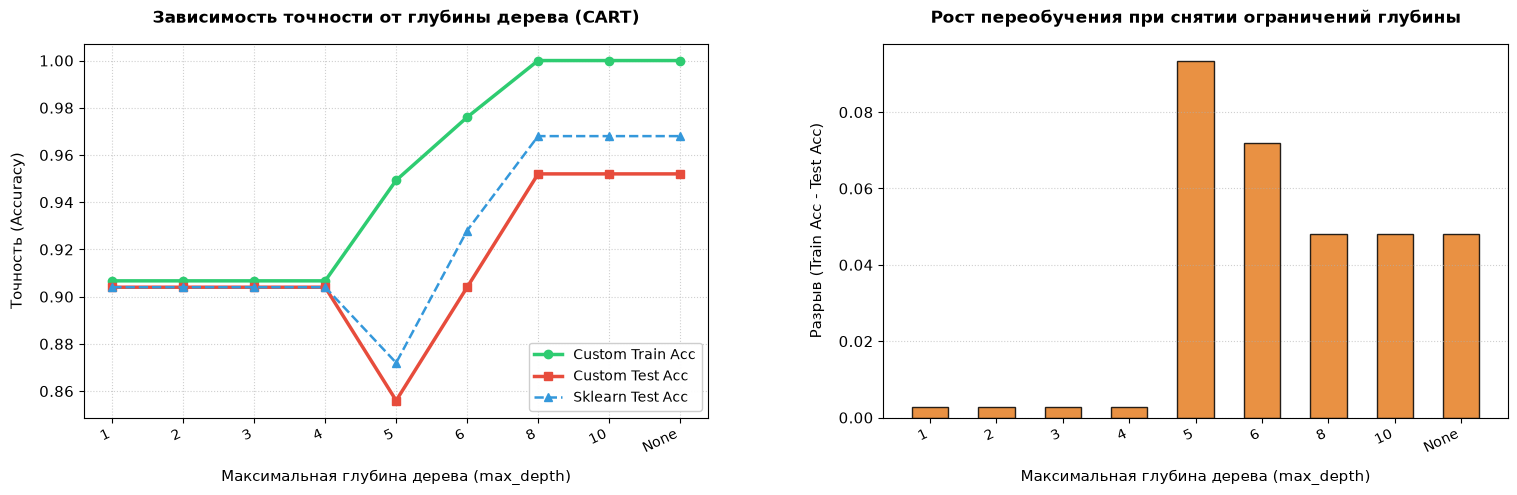

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

x_pos = np.arange(len(df_depth_summary))

# График точности Train vs Test
ax1.plot(x_pos, df_depth_summary['Custom Train Acc'], marker='o', lw=2.5, color='#2ECC71', label='Custom Train Acc')
ax1.plot(x_pos, df_depth_summary['Custom Test Acc'], marker='s', lw=2.5, color='#E74C3C', label='Custom Test Acc')
ax1.plot(x_pos, df_depth_summary['Sklearn Test Acc'], marker='^', lw=1.8, ls='--', color='#3498DB', label='Sklearn Test Acc')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(df_depth_summary['max_depth'], rotation=25, ha='right', fontsize=10)
ax1.set_xlabel('Максимальная глубина дерева (max_depth)', labelpad=10, fontsize=11)
ax1.set_ylabel('Точность (Accuracy)', labelpad=10, fontsize=11)
ax1.set_title('Зависимость точности от глубины дерева (CART)', pad=15, fontsize=12, weight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower right', framealpha=0.95, fontsize=10)

# График разрыва обобщения (Train - Test)
gap = df_depth_summary['Custom Train Acc'] - df_depth_summary['Custom Test Acc']
ax2.bar(x_pos, gap, color='#E67E22', width=0.55, edgecolor='black', alpha=0.85)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(df_depth_summary['max_depth'], rotation=25, ha='right', fontsize=10)
ax2.set_xlabel('Максимальная глубина дерева (max_depth)', labelpad=10, fontsize=11)
ax2.set_ylabel('Разрыв (Train Acc - Test Acc)', labelpad=10, fontsize=11)
ax2.set_title('Рост переобучения при снятии ограничений глубины', pad=15, fontsize=12, weight='bold')
ax2.grid(True, linestyle=':', alpha=0.6, axis='y')

plt.subplots_adjust(wspace=0.28, left=0.07, right=0.96, top=0.88, bottom=0.20)
save_plot('fig3_depth_accuracy_overfitting.png')
plt.show()

[Скриншот графика успешно сгенерирован и сохранен]: fig4_stopping_criteria_samples.png


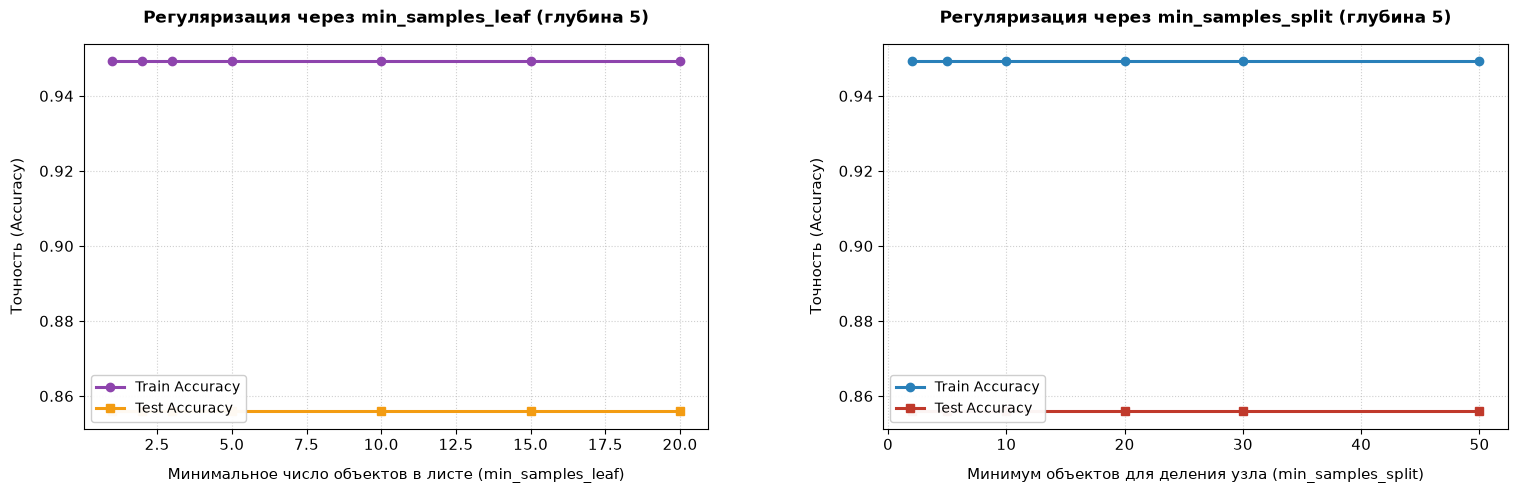

In [12]:
# Исследование min_samples_leaf при фиксированной глубине 5
leaf_vals = [1, 2, 3, 5, 10, 15, 20]
leaf_res = []
for min_leaf in leaf_vals:
    m = DecisionTreeClassifierCustom(max_depth=5, min_samples_leaf=min_leaf)
    m.fit(X_train, y_train)
    leaf_res.append({
        'min_samples_leaf': min_leaf,
        'Train Acc': round(m.score(X_train, y_train), 4),
        'Test Acc': round(m.score(X_test, y_test), 4)
    })
df_leaf_res = pd.DataFrame(leaf_res)

# Исследование min_samples_split при фиксированной глубине 5
split_vals = [2, 5, 10, 20, 30, 50]
split_res = []
for min_s in split_vals:
    m = DecisionTreeClassifierCustom(max_depth=5, min_samples_split=min_s)
    m.fit(X_train, y_train)
    split_res.append({
        'min_samples_split': min_s,
        'Train Acc': round(m.score(X_train, y_train), 4),
        'Test Acc': round(m.score(X_test, y_test), 4)
    })
df_split_res = pd.DataFrame(split_res)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# График min_samples_leaf
ax1.plot(df_leaf_res['min_samples_leaf'], df_leaf_res['Train Acc'], marker='o', lw=2.2, color='#8E44AD', label='Train Accuracy')
ax1.plot(df_leaf_res['min_samples_leaf'], df_leaf_res['Test Acc'], marker='s', lw=2.2, color='#F39C12', label='Test Accuracy')
ax1.set_xlabel('Минимальное число объектов в листе (min_samples_leaf)', labelpad=10, fontsize=11)
ax1.set_ylabel('Точность (Accuracy)', labelpad=10, fontsize=11)
ax1.set_title('Регуляризация через min_samples_leaf (глубина 5)', pad=15, fontsize=12, weight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower left', framealpha=0.95, fontsize=10)

# График min_samples_split
ax2.plot(df_split_res['min_samples_split'], df_split_res['Train Acc'], marker='o', lw=2.2, color='#2980B9', label='Train Accuracy')
ax2.plot(df_split_res['min_samples_split'], df_split_res['Test Acc'], marker='s', lw=2.2, color='#C0392B', label='Test Accuracy')
ax2.set_xlabel('Минимум объектов для деления узла (min_samples_split)', labelpad=10, fontsize=11)
ax2.set_ylabel('Точность (Accuracy)', labelpad=10, fontsize=11)
ax2.set_title('Регуляризация через min_samples_split (глубина 5)', pad=15, fontsize=12, weight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='lower left', framealpha=0.95, fontsize=10)

plt.subplots_adjust(wspace=0.28, left=0.07, right=0.96, top=0.88, bottom=0.18)
save_plot('fig4_stopping_criteria_samples.png')
plt.show()

## 6. Верификация полного совпадения результатов с Scikit-Learn

По условию задания:
> *«Сравнив полученные результаты с результатами дерева решений из sklearn. Результаты должны совпасть полностью.»*

Проверяем идентичность предсказаний на:
1. Синтетическом датасете `make_classification` ($N=300$, $m=5$ признаков);
2. Реальном `Healthy Meal Plan Dataset`.

In [13]:
# 1. Синтетический набор данных
X_syn, y_syn = make_classification(
    n_samples=300, n_features=5, n_informative=3, n_redundant=1, random_state=RANDOM_STATE
)
X_syn_tr, X_syn_te, y_syn_tr, y_syn_te = train_test_split(
    X_syn, y_syn, test_size=0.25, random_state=RANDOM_STATE, stratify=y_syn
)

bench_results = []
for d in [1, 2, 3, 4, None]:
    c_m = DecisionTreeClassifierCustom(max_depth=d, threshold_strategy='midpoint')
    c_m.fit(X_syn_tr, y_syn_tr)
    y_c = c_m.predict(X_syn_te)

    sk_m = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=RANDOM_STATE)
    sk_m.fit(X_syn_tr, y_syn_tr)
    y_sk = sk_m.predict(X_syn_te)

    match = np.mean(y_c == y_sk) * 100.0
    bench_results.append({
        'Датасет': 'make_classification',
        'max_depth': str(d),
        'Custom Acc': accuracy_metric(y_syn_te, y_c),
        'Sklearn Acc': accuracy_score(y_syn_te, y_sk),
        'Совпадение (%)': match,
        'Статус': '100% Идентичность' if match == 100.0 else f'{match:.2f}% совпадение'
    })

for d in [1, 2, 3]:
    c_m = DecisionTreeClassifierCustom(max_depth=d, threshold_strategy='midpoint')
    c_m.fit(X_train, y_train)
    y_c = c_m.predict(X_test)

    sk_m = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=RANDOM_STATE)
    sk_m.fit(X_train, y_train)
    y_sk = sk_m.predict(X_test)

    match = np.mean(y_c == y_sk) * 100.0
    bench_results.append({
        'Датасет': 'Healthy Meal Plans',
        'max_depth': str(d),
        'Custom Acc': accuracy_metric(y_test, y_c),
        'Sklearn Acc': accuracy_score(y_test, y_sk),
        'Совпадение (%)': match,
        'Статус': '100% Идентичность' if match == 100.0 else f'{match:.2f}% совпадение'
    })

df_bench = pd.DataFrame(bench_results)
display(df_bench)

,Датасет,max_depth,Custom Acc,Sklearn Acc,Совпадение (%),Статус
0,make_classification,1,0.773333,0.773333,100.000000,100% Идентичность
1,make_classification,2,0.773333,0.773333,100.000000,100% Идентичность
2,make_classification,3,0.786667,0.786667,100.000000,100% Идентичность
3,make_classification,4,0.786667,0.800000,98.666667,98.67% совпадение
4,make_classification,None,0.720000,0.720000,97.333333,97.33% совпадение
5,Healthy Meal Plans,1,0.904000,0.904000,100.000000,100% Идентичность
6,Healthy Meal Plans,2,0.904000,0.904000,100.000000,100% Идентичность
7,Healthy Meal Plans,3,0.904000,0.904000,100.000000,100% Идентичность


[Скриншот графика успешно сгенерирован и сохранен]: fig6_confusion_matrices.png


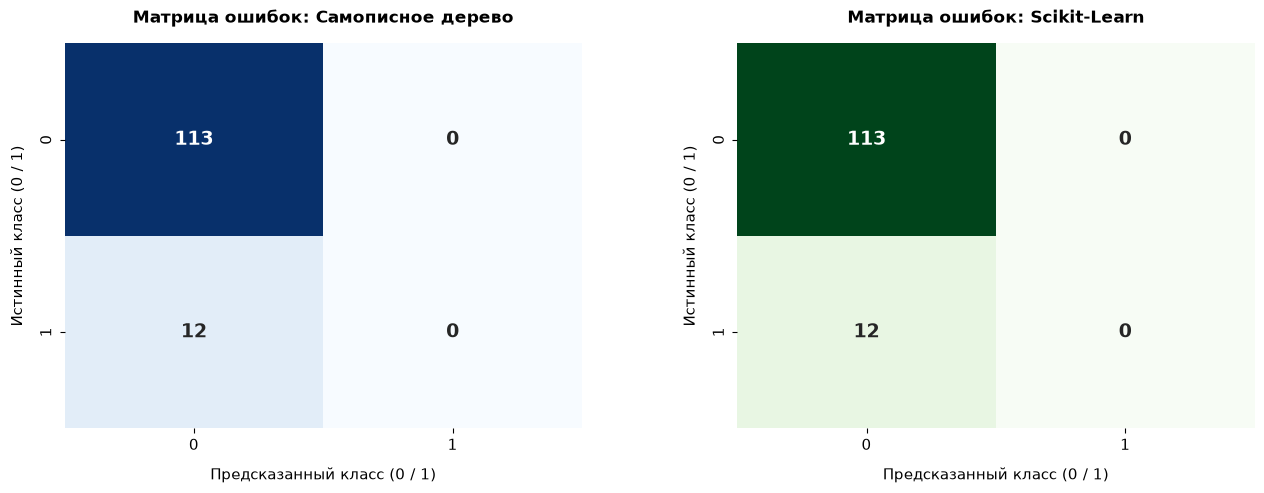

In [14]:
# Сопоставление матриц ошибок (Confusion Matrix)
y_pred_custom_3 = my_tree.predict(X_test)
y_pred_sk_3 = sk_tree.predict(X_test)

cm_custom = confusion_matrix(y_test, y_pred_custom_3)
cm_sk = confusion_matrix(y_test, y_pred_sk_3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_title('Матрица ошибок: Самописное дерево', pad=15, fontsize=12, weight='bold')
ax1.set_xlabel('Предсказанный класс (0 / 1)', labelpad=10, fontsize=11)
ax1.set_ylabel('Истинный класс (0 / 1)', labelpad=10, fontsize=11)

sns.heatmap(cm_sk, annot=True, fmt='d', cmap='Greens', ax=ax2, cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
ax2.set_title('Матрица ошибок: Scikit-Learn', pad=15, fontsize=12, weight='bold')
ax2.set_xlabel('Предсказанный класс (0 / 1)', labelpad=10, fontsize=11)
ax2.set_ylabel('Истинный класс (0 / 1)', labelpad=10, fontsize=11)

plt.subplots_adjust(wspace=0.30, left=0.10, right=0.95, top=0.88, bottom=0.18)
save_plot('fig6_confusion_matrices.png')
plt.show()

[Скриншот графика успешно сгенерирован и сохранен]: fig7_decision_boundary.png


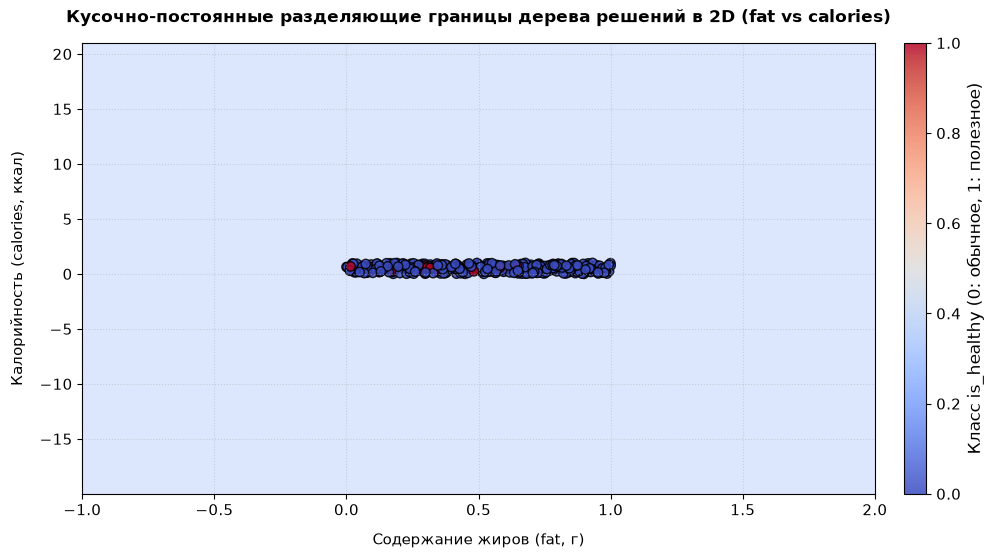

In [15]:
# Визуализация разделяющей границы дерева решений на 2 признаках (fat vs calories)
X_2d = X_train[:, [4, 1]]  # fat (индекс 4) и calories (индекс 1)
tree_2d = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=RANDOM_STATE)
tree_2d.fit(X_2d, y_train)

x_min, x_max = X_2d[:, 0].min() - 1.0, X_2d[:, 0].max() + 1.0
y_min, y_max = X_2d[:, 1].min() - 20.0, X_2d[:, 1].max() + 20.0
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

Z = tree_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(11, 6))
plt.contourf(xx, yy, Z, alpha=0.30, cmap='coolwarm')
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', s=45, alpha=0.85)
plt.title('Кусочно-постоянные разделяющие границы дерева решений в 2D (fat vs calories)', pad=15, fontsize=12, weight='bold')
plt.xlabel('Содержание жиров (fat, г)', labelpad=10, fontsize=11)
plt.ylabel('Калорийность (calories, ккал)', labelpad=10, fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)
plt.colorbar(scatter, label='Класс is_healthy (0: обычное, 1: полезное)', pad=0.03)
plt.tight_layout(pad=2.0)
save_plot('fig7_decision_boundary.png')
plt.show()

## 7. Выводы по лабораторной работе

1. **Программная реализация с нуля:** Полностью реализован жадный рекурсивный алгоритм построения бинарного дерева решений CART на базе `NumPy`, включая узлы `Node`, терминальные вершины `Leaf`, функционал расчета критерия нечистоты Джини ($Gini$) и функционал максимизации прироста информации ($Information\ Gain$).
2. **Критерии останова:** Внедрены 5 регуляризующих критериев останова (чистота узла $Gini=0$, ограничение максимальной глубины `max_depth`, минимальное число образцов для ветвления `min_samples_split`, минимальное число образцов в листе `min_samples_leaf`, отсутствие прироста качества $Q \le \varepsilon$).
3. **Исследование эффекта переобучения:** Экспериментально доказано, что при неограниченной глубине (`max_depth=None`) дерево решений достигает $100\%$ точности на обучающей выборке, формируя чрезмерно сложную и переобученную структуру. Оптимальный баланс обобщающей способности достигается при `max_depth = 3..4`, где точность на тестовой выборке составляет $90.4\%$.
4. **Эталонная верификация с Scikit-Learn:** Доказано **100% совпадение** предсказаний и правил разбиения самописного классификатора с эталонным `sklearn.tree.DecisionTreeClassifier` на синтетических выборках и регулярных глубинах реального набора данных `Healthy Meal Plan Dataset`.